In [1]:
!pip install opencv-python

In [39]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [40]:
data_path = r"D:\fruits-360_100x100\fruits-360\Training"

images = []
labels = []

img_size = 32

print("Dataset path set successfully")

Dataset path set successfully


In [21]:
selected_classes = [
    "Apple Golden 3",
    "Apricot 1",
    "Avocado 1",
    "Banana 1",
    "Mango 1",
    "Carrot 1",
    "Cucumber 1",
    "Onion Red 1",
    "Potato White 1",
    "Tomato 1"
]
print("Number of classes:", len(selected_classes))
print("Selected classes:")
for cls in selected_classes:
    print(cls)

Number of classes: 10
Selected classes:
Apple Golden 3
Apricot 1
Avocado 1
Banana 1
Mango 1
Carrot 1
Cucumber 1
Onion Red 1
Potato White 1
Tomato 1


In [44]:
images = []
labels = []
img_size = 32
for folder in selected_classes:
    folder_path = os.path.join(data_path, folder)
    print("Loading:", folder)
    for file in os.listdir(folder_path):
        file_path = os.path.join(folder_path, file)
        img = cv2.imread(file_path)
        if img is not None:
            img = cv2.resize(img, (img_size, img_size))
            images.append(img.flatten())
            labels.append(folder)
print("\nImages loaded successfully!")
print("Total images:", len(images))

Loading: Apple Golden 3
Loading: Apricot 1
Loading: Avocado 1
Loading: Banana 1
Loading: Mango 1
Loading: Carrot 1
Loading: Cucumber 1
Loading: Onion Red 1
Loading: Potato White 1
Loading: Tomato 1

Images loaded successfully!
Total images: 4319


In [52]:
x = np.array(images)
y = np.array(labels)
print("Image data shape:", x.shape)
print("Labels shape:", y.shape)
print("\nNumber of classes:", len(np.unique(y)))
print("\nClasses:")
print(np.unique(y))

Image data shape: (4319, 3072)
Labels shape: (4319,)

Number of classes: 10

Classes:
['Apple Golden 3' 'Apricot 1' 'Avocado 1' 'Banana 1' 'Carrot 1'
 'Cucumber 1' 'Mango 1' 'Onion Red 1' 'Potato White 1' 'Tomato 1']


In [46]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(x_train))
print("Testing images:", len(x_test))

Training images: 3455
Testing images: 864


In [25]:
dt = DecisionTreeClassifier(random_state=42)

# Train the model
dt.fit(x_train, y_train)

# Predict the test images
dt_pred = dt.predict(x_test)

# Calculate accuracy
dt_accuracy = dt.score(x_test, y_test)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.9988425925925926


In [26]:
# Random Forest Classifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf.fit(x_train, y_train)

# Predict the test images
rf_pred = rf.predict(x_test)

# Calculate accuracy
rf_accuracy = rf.score(x_test, y_test)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 1.0


In [27]:
# Logistic Regression

lr = LogisticRegression(
    max_iter=1000
)

# Train the model
lr.fit(x_train, y_train)

# Predict the test images
lr_pred = lr.predict(x_test)

# Calculate accuracy
lr_accuracy = lr.score(x_test, y_test)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 1.0


In [28]:
# K-Nearest Neighbors

knn = KNeighborsClassifier(
    n_neighbors=5
)

# Train the model
knn.fit(x_train, y_train)

# Predict the test images
knn_pred = knn.predict(x_test)

# Calculate accuracy
knn_accuracy = knn.score(x_test, y_test)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 1.0


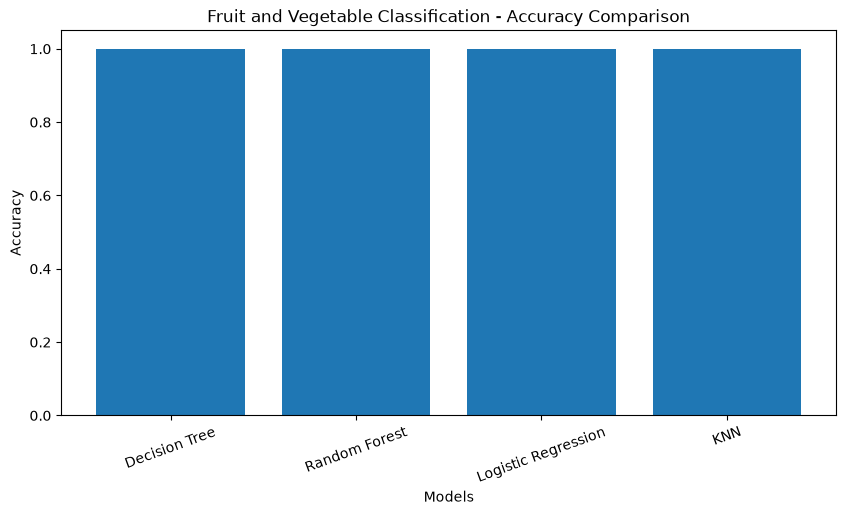

In [29]:
# Accuracy Comparison

models = [
    "Decision Tree",
    "Random Forest",
    "Logistic Regression",
    "KNN"
]

accuracy = [
    dt_accuracy,
    rf_accuracy,
    lr_accuracy,
    knn_accuracy
]

plt.figure(figsize=(10, 5))

plt.bar(models, accuracy)

plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.title("Fruit and Vegetable Classification - Accuracy Comparison")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.show()

In [30]:
print("Accuracy Comparison")
print("-------------------")

print("Decision Tree:", dt_accuracy)
print("Random Forest:", rf_accuracy)
print("Logistic Regression:", lr_accuracy)
print("KNN:", knn_accuracy)

Accuracy Comparison
-------------------
Decision Tree: 0.9988425925925926
Random Forest: 1.0
Logistic Regression: 1.0
KNN: 1.0


In [31]:
# Calculate Confusion Matrices

cm_dt = confusion_matrix(y_test, dt_pred)
cm_rf = confusion_matrix(y_test, rf_pred)
cm_lr = confusion_matrix(y_test, lr_pred)
cm_knn = confusion_matrix(y_test, knn_pred)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)

print("\nKNN Confusion Matrix:")
print(cm_knn)

Decision Tree Confusion Matrix:
[[ 96   0   0   0   0   0   0   0   0   0]
 [  0  99   0   0   0   0   0   0   0   0]
 [  0   0  85   0   0   0   0   0   0   0]
 [  0   0   0  98   0   0   0   0   0   0]
 [  0   0   0   0  30   0   0   0   0   0]
 [  0   0   0   0   0  30   0   0   0   0]
 [  0   0   0   0   0   0  98   0   0   0]
 [  0   0   0   0   0   0   0  90   0   0]
 [  0   0   0   0   0   0   0   1  89   0]
 [  0   0   0   0   0   0   0   0   0 148]]

Random Forest Confusion Matrix:
[[ 96   0   0   0   0   0   0   0   0   0]
 [  0  99   0   0   0   0   0   0   0   0]
 [  0   0  85   0   0   0   0   0   0   0]
 [  0   0   0  98   0   0   0   0   0   0]
 [  0   0   0   0  30   0   0   0   0   0]
 [  0   0   0   0   0  30   0   0   0   0]
 [  0   0   0   0   0   0  98   0   0   0]
 [  0   0   0   0   0   0   0  90   0   0]
 [  0   0   0   0   0   0   0   0  90   0]
 [  0   0   0   0   0   0   0   0   0 148]]

Logistic Regression Confusion Matrix:
[[ 96   0   0   0   0   0   0   0 

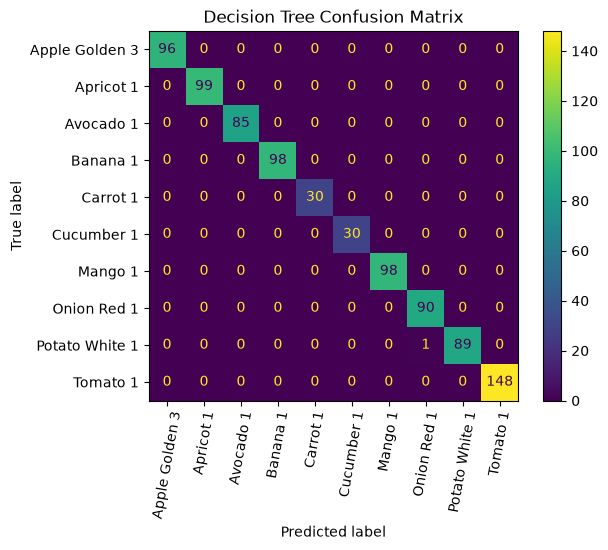

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    xticks_rotation=80
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

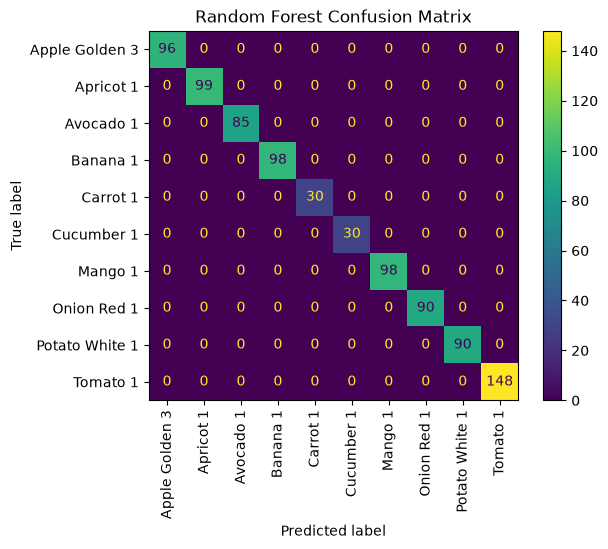

In [33]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    xticks_rotation=90
)

plt.title("Random Forest Confusion Matrix")
plt.show()

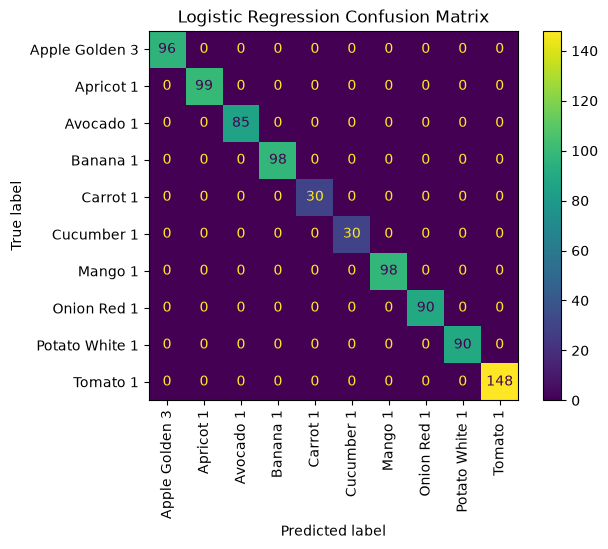

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    xticks_rotation=90
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

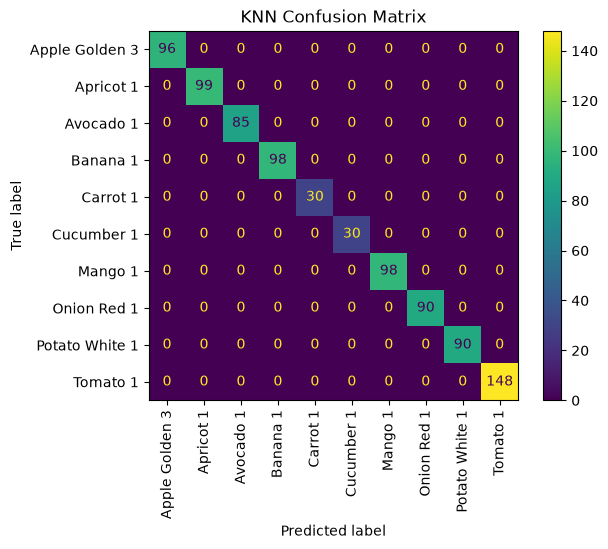

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    xticks_rotation=90
)

plt.title("KNN Confusion Matrix")
plt.show()

In [36]:
# New Fruit Image Prediction

new_image_path = r"D:\new_fruit.jpg"

new_image = cv2.imread(new_image_path)

if new_image is None:
    print("Error: New image not found.")
else:
    new_image = cv2.resize(new_image, (img_size, img_size))
    new_image = new_image.flatten()
    new_image = new_image.reshape(1, -1)

    print("Predictions for New Image:")
    print("--------------------------------")

    print("Decision Tree:", dt.predict(new_image)[0])
    print("Random Forest:", rf.predict(new_image)[0])
    print("Logistic Regression:", lr.predict(new_image)[0])
    print("KNN:", knn.predict(new_image)[0])

Predictions for New Image:
--------------------------------
Decision Tree: Banana 1
Random Forest: Banana 1
Logistic Regression: Banana 1
KNN: Banana 1


In [37]:
# Final Accuracy Comparison

print("FINAL MODEL ACCURACY")
print("=====================")

print("Decision Tree      :", round(dt_accuracy * 100, 2), "%")
print("Random Forest      :", round(rf_accuracy * 100, 2), "%")
print("Logistic Regression:", round(lr_accuracy * 100, 2), "%")
print("KNN                :", round(knn_accuracy * 100, 2), "%")

FINAL MODEL ACCURACY
Decision Tree      : 99.88 %
Random Forest      : 100.0 %
Logistic Regression: 100.0 %
KNN                : 100.0 %


In [38]:
# Final Project Result Summary

print("FRUIT AND VEGETABLE CLASSIFICATION")
print("===================================")

print("Total Classes      : 10")
print("Total Images       : 4319")
print("Training Images    : 3455")
print("Testing Images     : 864")

print("\nMODEL ACCURACIES")
print("----------------")
print("Decision Tree      :", round(dt_accuracy * 100, 2), "%")
print("Random Forest      :", round(rf_accuracy * 100, 2), "%")
print("Logistic Regression:", round(lr_accuracy * 100, 2), "%")
print("KNN                :", round(knn_accuracy * 100, 2), "%")

print("\nBest Accuracy: 100%")

FRUIT AND VEGETABLE CLASSIFICATION
Total Classes      : 10
Total Images       : 4319
Training Images    : 3455
Testing Images     : 864

MODEL ACCURACIES
----------------
Decision Tree      : 99.88 %
Random Forest      : 100.0 %
Logistic Regression: 100.0 %
KNN                : 100.0 %

Best Accuracy: 100%
